# Audio Preprocessing - Embedding Extraction

This notebook documents the audio preprocessing pipeline: resolving recording paths, and extracting pretrained embeddings via **OpenL3** (transfer learning), given the small dataset size (109 recordings, 79 unique cantaores) makes training an encoder from scratch impractical.

Due to local hardware constraints (8GB RAM MacBook Air, kernel panic during local extraction), the actual extraction ran on Google Colab (GPU-accelerated), with results saved incrementally to Google Drive and brought back locally. This notebook documents the pipeline design and loads the final result.

## Approach: transfer learning with OpenL3

Rather than training a CNN from scratch, infeasible with ~157 raw recordings across 79 cantaores. We use **OpenL3** (via `torchopenl3`, a PyTorch reimplementation), a model pretrained on general audio-visual correspondence, configured for the `music` content type. This follows standard practice in low-resource audio tasks: leveraging a pretrained representation and fine-tuning a small head on top, rather than learning representations from raw audio directly.

OpenL3 outputs one 512-dimensional embedding per ~1-second window, not one per recording. Two representations are derived from this:
- **Window-level embeddings**: kept for training the future contrastive/triplet loss head - multiplying the number of same-cantaor training examples well beyond the 109 recordings available.
- **Recording-level embeddings** (mean-pooled across windows): used for evaluation (EER, ROC) and visualization (UMAP), where one comparable vector per recording is needed.

In [19]:
import numpy as np
import pandas as pd

data = np.load('data/processed/recording_embeddings.npz', allow_pickle=True)

embeddings_df = pd.DataFrame({
    'recording_id': data['recording_id'],
    'norm_name': data['norm_name'],
    'source': data['source'],
    'split': data['split'],
})
embeddings_df['embedding'] = list(data['embeddings'])

print(f"Total recordings: {len(embeddings_df)}")
print(f"Embedding dimension: {data['embeddings'].shape[1]}")
embeddings_df.head()

Total recordings: 109
Embedding dimension: 512


,recording_id,norm_name,source,split,embedding
0,001_FernandoTerremoto_Fandangos.mp3,fernandoterremoto,cante100,train,"[2.751371, 2.938057, 3.127231, 2.611294, 2.014..."
1,002_ManuelSotoSordera_Fandangos.mp3,manuelsotosordera,cante100,train,"[2.707405, 2.5394413, 3.4479544, 2.331297, 1.8..."
2,003_RafaelRomero_Fandangos.mp3,rafaelromero,cante100,test,"[2.5077033, 3.1434534, 3.3416865, 2.4208188, 2..."
3,004_ManuelSotoSordera_Fandangos.mp3,manuelsotosordera,cante100,train,"[2.8168435, 3.2020967, 3.5799184, 2.1256964, 2..."
4,005_Fosforito_Fandangos.mp3,fosforito,cante100,train,"[2.4736826, 3.0316849, 3.3751533, 2.3131037, 2..."


In [20]:
print(embeddings_df['split'].value_counts())
print()
print(f"Embeddings con NaN: {sum(np.isnan(e).any() for e in embeddings_df['embedding'])}")
print(f"Cantaores únicos: {embeddings_df['norm_name'].nunique()}")

split
train    78
test     31
Name: count, dtype: int64

Embeddings con NaN: 0
Cantaores únicos: 31


## Note on execution environment

Extraction ran on Google Colab (GPU T4 runtime) rather than locally, due to memory constraints on the available hardware (8GB RAM) when loading the OpenL3 model alongside PyTorch. Audio files and catalog CSVs were uploaded to Google Drive; window-level embeddings were saved incrementally per recording (`.npy` files) to guard against session interruptions, then mean-pooled into a single `recording_embeddings.npz` file and brought back to the local project for downstream work.

This kind of local-to-cloud handoff for compute-heavy steps, while keeping data exploration and analysis local, is a common and practical pattern when working with limited hardware, worth noting explicitly here rather than hiding it.

In [21]:
!pip install umap-learn -q

Python(18474) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


## Quick visualization: UMAP of pretrained OpenL3 embeddings

Before any fine-tuning, we visualize the raw OpenL3 embeddings (mean-pooled per recording) with UMAP, colored by cantaor. This is a sanity check, not a final result: OpenL3 was never trained to distinguish cantaores specifically, so we don't expect clean clustering yet, but any visible grouping suggests the pretrained representation already captures *some* relevant structure, worth building on.

umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


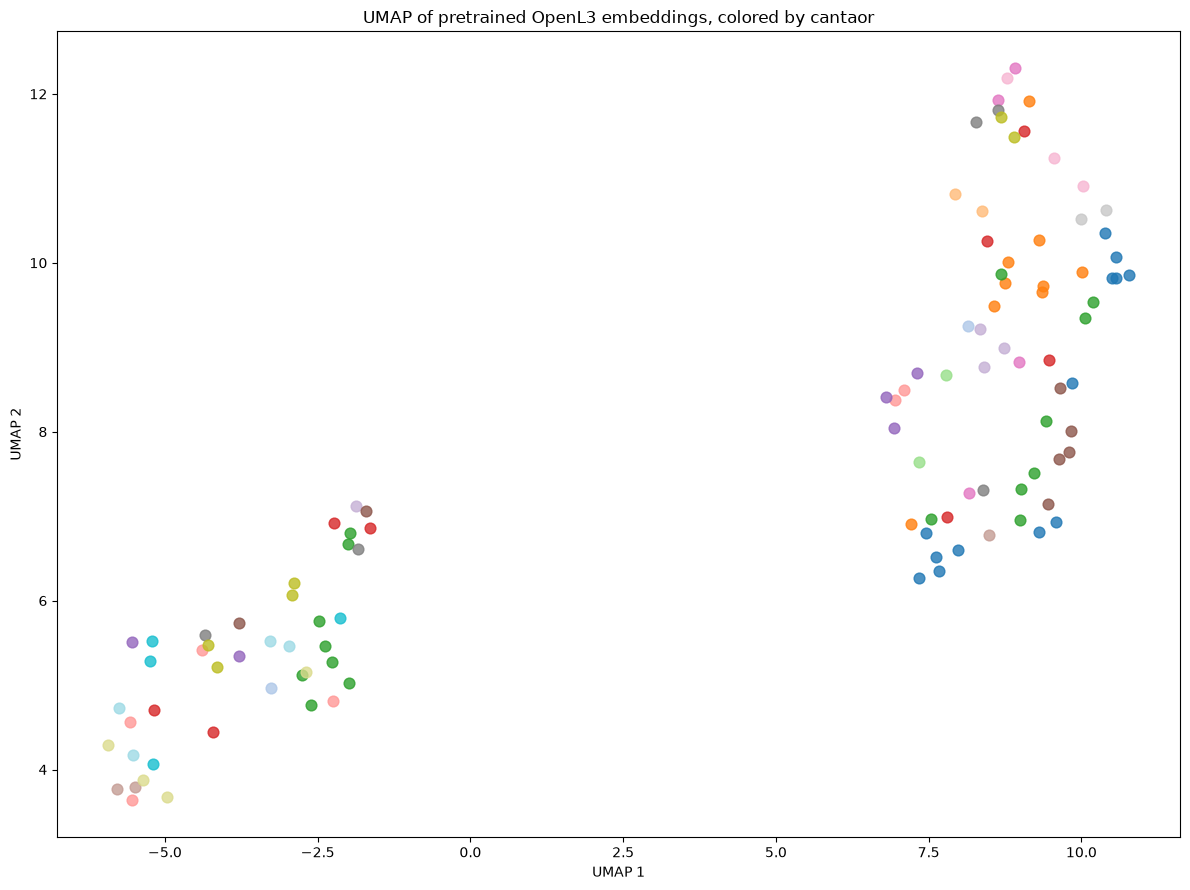

In [22]:
import umap
import matplotlib.pyplot as plt
import numpy as np

reducer = umap.UMAP(n_neighbors=10, min_dist=0.3, random_state=42)
embedding_2d = reducer.fit_transform(np.stack(embeddings_df['embedding'].values))

fig, ax = plt.subplots(figsize=(12, 9))
cantaores = embeddings_df['norm_name'].unique()
colors = plt.cm.tab20(np.linspace(0, 1, len(cantaores)))
color_map = dict(zip(cantaores, colors))

for cantaor in cantaores:
    mask = embeddings_df['norm_name'] == cantaor
    ax.scatter(embedding_2d[mask, 0], embedding_2d[mask, 1],
               label=cantaor, color=color_map[cantaor], s=60, alpha=0.8)

ax.set_title('UMAP of pretrained OpenL3 embeddings, colored by cantaor')
ax.set_xlabel('UMAP 1')
ax.set_ylabel('UMAP 2')
plt.tight_layout()
plt.savefig('data/processed/umap_pretrained.png', dpi=150)
plt.show()

## Interpretation

The pretrained OpenL3 embedding space shows loose global structure (two broad regions), but no visible per-cantaor clustering. Colors are mixed within each region. This is expected: OpenL3 was pretrained for general audio-visual correspondence, not cantaor identity, so it captures broad acoustic structure (likely related to instrumentation, palo type, or recording characteristics) rather than singer-specific style.

This UMAP serves as a baseline "before" snapshot. The next step — training a contrastive/triplet loss head on top of these embeddings - is what should introduce cantaor-specific structure into the space. Comparing this baseline against the UMAP of the *fine-tuned* embeddings later will be the clearest visual evidence of whether the fine-tuning step actually learned something meaningful.